# Home assigment 1

Please give your name below:

In [1]:
name='Lê Huỳnh Thiện Nhân'

# Exercise 3

You will work a bit more with reading ASCII files (I can attest, this is a routine daily task for a nuclear reactor analyst). In the attached folder (called 'train') you find several spent nuclear fuel inventories generated with the Monte Carlo transport code Serpent2. You will learn later during the course more about spent nuclear fuel, in this exercise you will need to focus only on scripting. The naming convention of the files within the folder describes the burnup or BU (ie. how long the fuel was in the reactor, and how much energy was released from it) and cooling time or CT (ie. how long the fuel was cooled after irradiation): for example 'trainBU46.00CT26.18.bumat2' belongs to a case where the burnup was 46.00 MWd/kgU and the fuel was cooled for 26.18 years after leaving the reactor. Note, that the files also contain burnup and time information, however that time is not just the cooling time, it also includes the time the fuel spent in the reactor.

The isotopes are listed with their ZAID (ie. an ID constructed as $Z\cdot1000+A$) in the files, all ending with '.15c' which refers to the temperature in the calculation, not relevant for your task. For example U235 you will find as '92235.15c'. The inventory is given as atomic concentrations for each nuclide with units $b^{-1}cm^{-1}=\frac{1}{b\cdot cm}=\frac{1}{10^{-24}cm^3}=\frac{10^{24}}{cm^3}$.  

1. Write a function which receives a filename as an input and then extracts the file content into a dictionary. Store both the concentrations and the burnup/cooling time information based on the filenames. Then apply this function to all the files (hint: you can use `os.listdir(foldername)` to list the files in the folder, for this you have to `import os`. You can read about the `os` package at [the documentation site](https://docs.python.org/3/library/os.html).)

2. Plot the concentration of Cs-137 against burnup with 'x' markers. Use 
    - blue marker if the cooling time is between 5 and 10 years.
    - red marker if the cooling time is between 10 and 15 years.
    - green marker if the cooling time is between 15 and 20 years
    - yellow marker if the cooling time is between 20 and 25 years
    - magenta marker if the cooling time is above 25 years
    - (Note you can use other colors if you prefer so, the important part is to use 5 distinct colors for these cooling time intervals).

3. Convert the concentrations to activity concentration (Bq/cm3) for Cs137, Cs134 and Eu154 (hint: you can look up the half-lifes from the internet, and make sure that you convert the units correctly). 
    - Plot the activity concentrations against burnup for the three isotopes in one figure. Use a legend.
    - Plot the activity concentrations after the fuel was removed from the reactor against burnup for the three isotopes in one figure. Use a legend. (Hint, you will need to use the cooling time information, and the decay law to figure out what was the activity before the cooling has started.)
    
4. Write a few sentences about your conclusions.

In [8]:
# Initialize 
import openmc
openmc.config['cross_sections'] = '/home/dell/endfb-vii.1-hdf5/cross_sections.xml'
import numpy as np
import matplotlib.pyplot as plt
import os
import re

In [15]:
# Defining key functions
def extract(file, folder  = './train'):
    dummy = re.search(r'BU(\d+)[._](\d+)CT(\d+)[._](\d+)',file)
    data = {'burnup': float(dummy.group(1) + '.' + dummy.group(2)),
           'cooling_time': float(dummy.group(3) + '.' + dummy.group(4)),
           'conc': {}
            }
    with open(os.path.join(folder, file)) as content:
        for lines in content:
            line = lines.split()
            if len(line) == 2 and line[0].endswith('.15c'):
                zaid = int(line[0].split('.')[0])
                data['conc'][zaid] = float(line[1])
    return data

def pick_color(time):
    if time <= 5:
        return 'grey'
    if 5 <= time < 10:
        return 'blue'
    if 10 <= time < 15:
        return 'red'
    if 15 <= time < 20:
        return 'green'
    if 20 <= time < 25:
        return 'yellow'
    else: 
        return 'magenta'

unit_dict = {'s':1,'m':60,'h':3600,'d':24*3600,'yr':24*3600*365.25}

def convert_conc(conc, hl, unit = 'yr'):
    lam = np.log(2)/(hl*unit_dict[unit])
    return conc*lam*1e24

def convert_conc_discharge(conc, hl, ct ,unit = 'yr'):
    lam = np.log(2)/(hl*unit_dict[unit])
    ct_s = ct * unit_dict[unit]
    return conc*lam*1e24*np.exp(lam*ct_s)

# Extract and process data
files = sorted(f for f in os.listdir(path = './train'))
inventories = {f: extract(f) for f in files}
burnup = np.array([d['burnup'] for d in inventories.values()])
ct = np.array([d['cooling_time'] for d in inventories.values()])
conc137 = np.array([d['conc'][55137] for d in inventories.values()])
conc134 = np.array([d['conc'][55134] for d in inventories.values()])
conc154 = np.array([d['conc'][63154] for d in inventories.values()])
hl137 = 30.17 #yrs
hl134 = 2.06 #yrs
hl154 = 8.59 #yrs

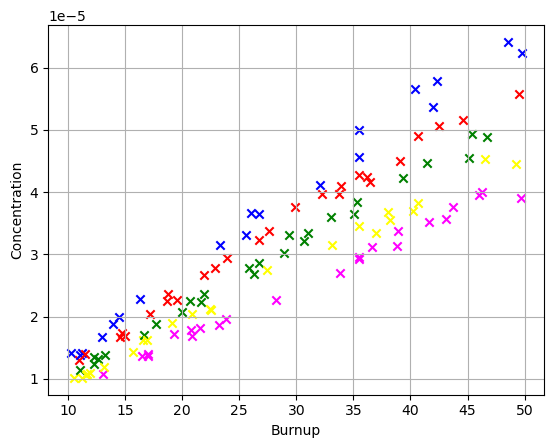

In [11]:
# Plot the 2nd requirement
plt.figure()
for bu, con, t in zip(burnup, conc137, ct):
    plt.scatter(bu, con, marker = 'x', color = pick_color(t))
plt.grid(True)
plt.ylabel('Concentration')
plt.xlabel('Burnup')
plt.show()

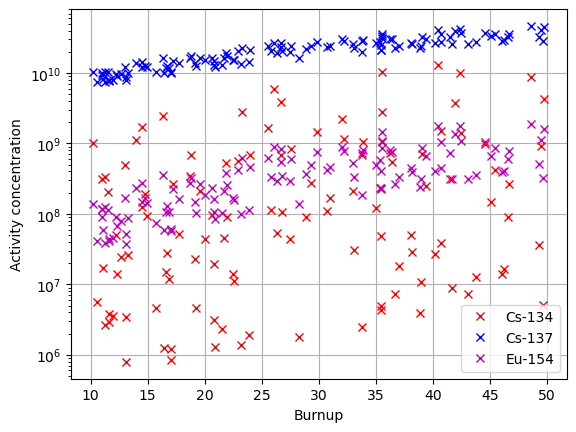

In [20]:
# Plot the 1st of the 3rd requirement
fig = plt.figure()
plt.plot(burnup, convert_conc(conc134,hl134),'rx')
plt.plot(burnup, convert_conc(conc137,hl137),'bx')
plt.plot(burnup, convert_conc(conc154,hl154),'mx')
plt.xlabel('Burnup')
plt.ylabel('Activity concentration')
plt.yscale("log")
plt.legend(['Cs-134','Cs-137','Eu-154'])
plt.grid(True)
plt.show()

**The activity concentrations we plotted against burnup was after the cooling, where the products of the fission decayed (Eu-154, Cs-134, Cs-137,...).**

**Now we want to plot the activity concentrations of them BUT right after the fuel was removed/stopped producing neutrons for fission, ie. discharge.**

Assuming those three isotopes didn't have any parents to feed their population, this is then just a simple case of decay, which means: 
$$A_{discharge} = A_{after}\cdot e^{\lambda\cdot t_{cooling}} $$
where $A_{after}$ is the A we JUST plotted on the previous plot 

**We want to plot this because of a particular situation:**\
Say two batches of fuel went through exactly the same irradiation, same burnup, so the reactor made exactly the same amount of Cs-134 in both. But one was cooled for 5 years and the other for 25 years. The files are snapshots at the end of cooling, so they look very different: 
- 5 y of cooling: Cs-134 has decayed to about 19% of what it was.
- 25 y of cooling: Cs-134 has decayed to about 0.02% of what it was.

My guess is that this is probably the reason why, on the previous plot, some isotopes like Cs-134 or Eu-154 (red and magenta markers) were bouncing around all over the place on the plot.

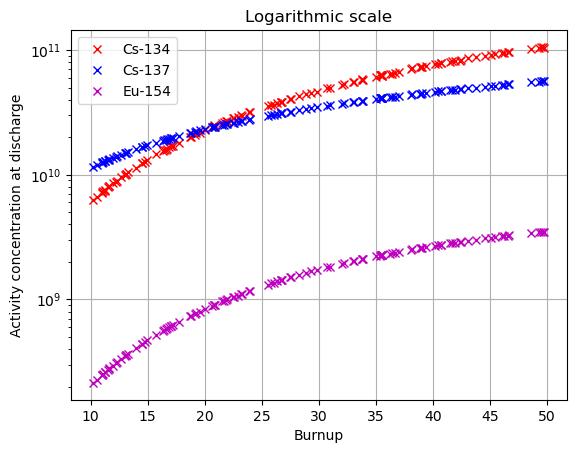

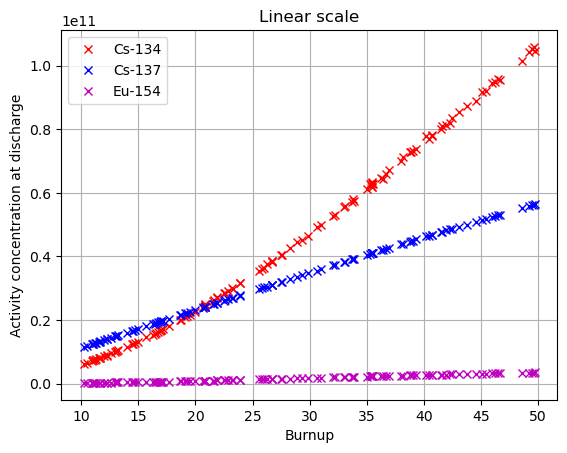

In [22]:
# Plot the 2nd of the 3rd requirement
plt.figure()
plt.plot(burnup, convert_conc_discharge(conc134,hl134, ct),'rx')
plt.plot(burnup, convert_conc_discharge(conc137,hl137, ct),'bx')
plt.plot(burnup, convert_conc_discharge(conc154,hl154, ct),'mx')
plt.xlabel('Burnup')
plt.ylabel('Activity concentration at discharge')
plt.legend(['Cs-134','Cs-137','Eu-154'])
plt.title('Logarithmic scale')
plt.yscale("log")
plt.grid(True)
plt.figure()
plt.plot(burnup, convert_conc_discharge(conc134,hl134, ct),'rx')
plt.plot(burnup, convert_conc_discharge(conc137,hl137, ct),'bx')
plt.plot(burnup, convert_conc_discharge(conc154,hl154, ct),'mx')
plt.xlabel('Burnup')
plt.ylabel('Activity concentration at discharge')
plt.legend(['Cs-134','Cs-137','Eu-154'])
plt.title('Linear scale')
plt.grid(True)
plt.show()

### The curves

Cs-137 (blue) grows roughly linearly with burnup. It’s a direct fission product, so twice the fissions means twice the Cs-137. The data goes from about 1.2e10 at BU 10 to about 5.5e10 at BU 50, a factor of ~4.6 for a 5× increase in burnup, which is slightly under linear since some Cs-137 decays during irradiation, and that loss grows with irradiation time.

Cs-134 (red) and Eu-154 (magenta) rise much faster (logarithmically, of course). Cs-134 goes from ~6e9 to ~1e11, a factor of ~16, and Eu-154 from ~2e8 to ~3.5e9, also ~16. A 5× burnup increase giving a ~16× increase means a power law with an exponent of around 1.7 to 2 (5^1.7 ≈ 15). 

This actually matches the capture-product picture: more of the parent isotope builds up (∝ BU), and more neutron exposure is available to capture on it (∝ BU), so you get ~BU².

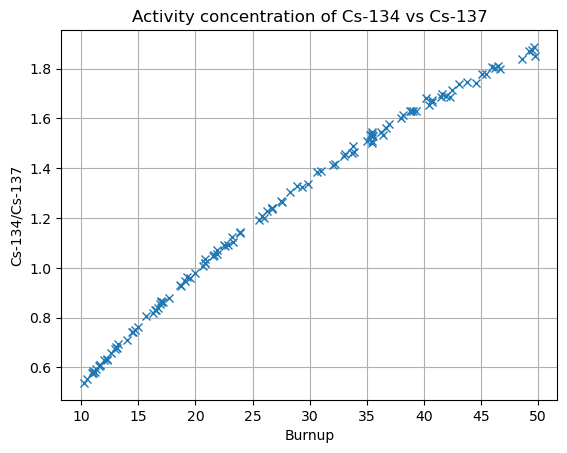

In [31]:
plt.figure()
plt.plot(burnup, convert_conc_discharge(conc134,hl134, ct)/convert_conc_discharge(conc137,hl137, ct),'x')
plt.xlabel('Burnup')
plt.ylabel('Cs-134/Cs-137')
plt.title('Activity concentration of Cs-134 vs Cs-137')
plt.grid(True)
plt.show()

### Why red overtakes blue

At low burnup (BU 10), Cs-137 sits above Cs-134, and they cross at around BU 20. After that, Cs-134 is higher. Two things are at play here:

Cs-134 grows faster with burnup (~BU² against ~BU¹), so its curve catches up to Cs-137’s. The ratio Cs-134/Cs-137 grows roughly linearly with burnup, and it crosses 1 around BU 20.
Activity isn’t the same as number of atoms. Cs-134 has a half-life of 2 years against 30 years for Cs-137, so each Cs-134 atom decays ~15 times more often. That means Cs-134 can have far fewer atoms and still match or beat Cs-137 in activity. At BU 50, Cs-134 is about 2× more active than Cs-137 but has only about 1/7 as many atoms (2 ÷ 15).

Which is why Cs-134/Cs-137 is a classic burnup indicator: the ratio changes strongly with burnup and doesn’t depend on how much fuel you have.